# Genetic Algorithms

The theory is in [README.md](./README.md) — selection, the crossover and mutation operators, and
when a genetic algorithm is worth reaching for. This notebook is only the code.

One engine, three problems: evolve a string toward a target, place eight queens, and evolve a
picture. Everything below the engine is a stub for you to fill in.

## Setup

In [1]:
from dataclasses import dataclass
from typing import Any, Callable, Optional
import math
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import clear_output

## What a problem looks like

Four functions. The engine below knows nothing else about what it is evolving — which is why the
same twenty lines run all three problems in this notebook.

`Individual` is whatever you are evolving: a string, an array of pixels, a list of row numbers.
The engine never inspects it, it only passes it back to your four functions.

In [2]:
Individual = Any
Population = list[Individual]


@dataclass
class GAProblem:
    random_individual: Callable[[], Individual]
    fitness: Callable[[Individual], float]
    crossover: Callable[[Individual, Individual], tuple[Individual, Individual]]
    mutate: Callable[[Individual, float], Individual]

    # optional: stop early once this is reached
    solved_at: Optional[float] = None

## The engine

Score, select, combine, perturb, repeat. This one is written out for you — it is the shape the
stubs below plug into.

Two details worth reading rather than skimming:

- **elitism**: the best few individuals are copied into the next generation untouched. Without it
  the best solution found so far can be destroyed by the very crossover that was supposed to
  improve on it, and the best fitness can go *down* between generations
- **the history**: every run returns the best fitness per generation. That curve is the thing you
  look at when a GA misbehaves — flat from the start means the fitness has no gradient, flat after
  a fast rise means it converged and mutation is too low

In [3]:
def evolve(problem: GAProblem,
           population_size: int = 100,
           generations: int = 200,
           mutation_rate: float = 0.05,
           elite: int = 2,
           on_generation: Optional[Callable[[int, Individual, float], None]] = None):
    """Run a genetic algorithm. Returns (best individual, best fitness, history)."""
    population = [problem.random_individual() for _ in range(population_size)]
    history = []

    for generation in range(generations):
        scored = sorted(population, key=problem.fitness, reverse=True)
        best = scored[0]
        best_fitness = problem.fitness(best)
        history.append(best_fitness)

        if on_generation is not None:
            on_generation(generation, best, best_fitness)

        if problem.solved_at is not None and best_fitness >= problem.solved_at:
            break

        # the best few survive untouched, so the best fitness can never drop
        next_population = scored[:elite]

        while len(next_population) < population_size:
            mother = select(scored, problem.fitness)
            father = select(scored, problem.fitness)
            left, right = problem.crossover(mother, father)
            next_population.append(problem.mutate(left, mutation_rate))
            if len(next_population) < population_size:
                next_population.append(problem.mutate(right, mutation_rate))

        population = next_population

    return best, best_fitness, history

## Selection

Pick one parent, favouring the fitter. Use a **tournament**: take `k` individuals at random and
return the best of them.

`k` is the whole tuning knob. `k = 1` is picking at random and applies no pressure at all; large
`k` nearly always returns the very best individual and the population collapses onto it within a
few generations.

In [4]:
def select(population: Population, fitness: Callable[[Individual], float], k: int = 3) -> Individual:
    """Tournament selection: the best of k individuals chosen at random."""
    return max(random.sample(population, k), key=fitness)

## Crossover

Two parents in, two children out. Both children must keep every gene in the position it came
from — that is the whole point, and it is the easy thing to get wrong.

For one-point crossover at position `i`:

    child 1 = mother[:i] + father[i:]
    child 2 = father[:i] + mother[i:]

Note the second one. It is the *head* of the father with the *tail* of the mother. Writing
`mother[i:] + father[:i]` gives a string of the right length whose genes have all moved, which
looks plausible and quietly destroys the search.

In [5]:
def one_point_crossover(mother: str, father: str) -> tuple[str, str]:
    """Split both parents at the same random position and swap the tails."""
    i = random.randrange(len(mother))
    child1 = mother[:i] + father[i:]
    child2 = father[:i] + mother[i:]
    return (child1,child2)


def uniform_crossover(mother: np.ndarray, father: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Decide independently for each gene which parent it comes from.

    Build a random boolean mask the same shape as the parents; child 1 takes the
    masked positions from the mother and the rest from the father, and child 2
    takes the opposite.
    """
    mask = np.random.random(mother.shape) < 0.5
    return np.where(mask, mother, father), np.where(mask, father, mother)

### More operators

Four more, and the point of having them side by side is that the right one is decided by the
**encoding**, not by which is cleverest.

- **Two-point** — swap the middle instead of the tail. Removes one-point's bias toward keeping
  each parent's two ends together.
- **Arithmetic** — for real-valued genes, blend rather than choose. Note what happens at
  `alpha = 0.5`: both children come out identical, so half your offspring are wasted.
- **PMX** and **cycle** — for permutations, where every value must appear exactly once. Cut a
  permutation anywhere with the operators above and you get duplicates and omissions.

PMX keeps *relative order*, cycle keeps *absolute position*. The worked examples in the README are
the tests below, so you can check yourself against them.

In [6]:
def two_point_crossover(mother, father):
    """Swap the section between two random points, keeping the ends."""
    i = random.randrange(len(mother))
    j = random.randrange(i, len(mother))    
    child1 = mother[:i] + father[i:j] + mother[j:]
    child2 = father[:i] + mother[i:j] + father[j:]
    return (child1,child2)

def arithmetic_crossover(mother: np.ndarray, father: np.ndarray, alpha: float = 0.5):
    """Blend two real-valued parents: alpha * one + (1 - alpha) * the other."""
    return (alpha*mother + (1-alpha) * father, (1-alpha)*mother + alpha * father)


def pmx(mother: list, father: list) -> tuple[list, list]:
    """Partially-mapped crossover, for permutations.

    Copy one parent's middle segment into the child. Fill the rest from the
    other parent, but whenever a value is already in the segment, follow the
    mapping the two segments imply until you reach one that is not.
    """
    n = len(mother)
    i, j = sorted(random.sample(range(n + 1), 2))
    def build(primary, secondary):
        child = [None] * n
        child[i:j] = primary[i:j]
        taken = set(child[i:j])
        for pos in [*range(0, i), *range(j, n)]:
            value = secondary[pos]
            while value in taken:
                value = secondary[primary.index(value)]
            child[pos] = value
        return child

    return build(mother, father), build(father, mother)


def cycle_crossover(mother: list, father: list) -> tuple[list, list]:
    """Cycle crossover, for permutations.

    Starting at a position, jump to wherever the father's value sits in the
    mother, and keep going until you return to the start -- that is one cycle.
    Take alternate cycles from alternate parents, so every position ends up
    holding a value one of its parents had there.
    """
    n = len(mother)
    at = {value: index for index, value in enumerate(mother)}
    child1, child2 = [None] * n, [None] * n
    seen = [False] * n
    cycle = 0
    for start in range(n):
        if seen[start]:
            continue
        positions, index = [], start
        while not seen[index]:
            seen[index] = True
            positions.append(index)
            index = at[father[index]]
        source = (mother, father) if cycle % 2 == 0 else (father, mother)
        for p in positions:
            child1[p], child2[p] = source[0][p], source[1][p]
        cycle += 1
    return child1, child2

In [7]:
# the worked examples from the README, as tests
p1, p2 = [1, 2, 3, 4, 5, 6, 7, 8, 9], [4, 5, 2, 1, 8, 7, 6, 9, 3]
random.seed(0)
print("PMX (segment 3:6 gives the README's example):")
print(" ", pmx(p1, p2))

q1, q2 = [1, 2, 3, 4, 5, 6, 7, 8], [2, 4, 6, 8, 7, 5, 3, 1]
print("cycle, expecting [1, 2, 6, 4, 7, 5, 3, 8] and [2, 4, 3, 8, 5, 6, 7, 1]:")
print(" ", cycle_crossover(q1, q2))

# whatever the parents, a permutation operator must return permutations
random.seed(1)
bad = 0
for _ in range(2000):
    n = random.randint(4, 12)
    a, b = random.sample(range(n), n), random.sample(range(n), n)
    for fn in (pmx, cycle_crossover):
        for child in fn(a, b):
            if sorted(child) != list(range(n)):
                bad += 1
print(f"\n2000 random pairs: {bad} invalid children")

PMX (segment 3:6 gives the README's example):
  ([4, 5, 2, 1, 3, 6, 7, 8, 9], [1, 2, 8, 4, 5, 7, 6, 9, 3])
cycle, expecting [1, 2, 6, 4, 7, 5, 3, 8] and [2, 4, 3, 8, 5, 6, 7, 1]:
  ([1, 2, 6, 4, 7, 5, 3, 8], [2, 4, 3, 8, 5, 6, 7, 1])

2000 random pairs: 0 invalid children


## Mutation

Crossover can only rearrange genes that are already somewhere in the population. Once every
individual has the same letter in some position, no crossover will ever change it. Mutation is the
only thing that can.

Each gene changes independently with probability `rate`. A reasonable starting point is `1 / L`
for length `L` — about one change per child.

In [8]:
def mutate_string(individual: str, rate: float, genes: str) -> str:
    """Replace each character with a random one from `genes`, with probability `rate`."""
    return "".join([c if random.random() > rate else random.choice(genes)  for c in individual])


def mutate_array(individual: np.ndarray, rate: float, low: int = 0, high: int = 256) -> np.ndarray:
    """Replace each entry with a random integer in [low, high), with probability `rate`.

    Work on a copy -- the elite individuals are shared with the next generation,
    and mutating one in place would corrupt them.
    """
    out = individual.copy()
    mask = np.random.random(individual.shape) < rate
    out[mask] = np.random.randint(low, high, int(mask.sum()), dtype=individual.dtype)
    return out   

## Problem 1: evolve a string

The classic toy. Fitness is the number of positions that already match the target, so a solution
scores `len(target)`.

This is a good fitness because it is **graded**: it tells you how close you are, not merely
whether you have arrived. Compare the whole string for equality instead and every individual
scores 0 until one scores 1, leaving the search nothing to climb.

In [9]:
GENES = "abcdefghijklmnopqrstuvwxyz "
TARGET = "the university of sofia"


def string_problem(target: str = TARGET, genes: str = GENES) -> GAProblem:
    return GAProblem(
        random_individual=lambda: "".join(random.choices(genes, k=len(target))),
        fitness=lambda s: sum(a == b for a, b in zip(s, target)),
        crossover=one_point_crossover,
        mutate=lambda s, rate: mutate_string(s, rate, genes),
        solved_at=len(target),
    )

In [10]:
random.seed(0)
problem = string_problem()


def report(generation, best, fitness):
    if generation % 20 == 0:
        print(f"  generation {generation:4}  fitness {fitness:3}/{len(TARGET)}  {best!r}")


best, fitness, history = evolve(problem, population_size=120, generations=400,
                                mutation_rate=0.02, on_generation=report)
print(f"\nbest after {len(history)} generations: {best!r}  ({fitness}/{len(TARGET)})")

  generation    0  fitness   5/23  'rkruuh oqrsesl t  wpqmj'
  generation   20  fitness  18/23  'the uxijersisy r  sofia'
  generation   40  fitness  22/23  'the university rf sofia'

best after 51 generations: 'the university of sofia'  (23/23)


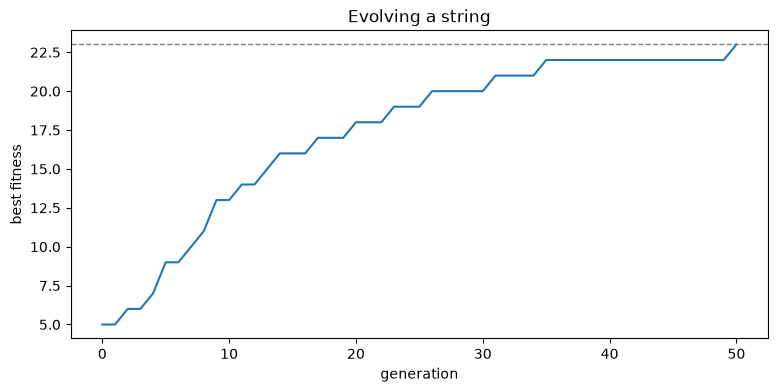

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(history)
plt.axhline(len(TARGET), linestyle="--", linewidth=1, color="grey")
plt.xlabel("generation")
plt.ylabel("best fitness")
plt.title("Evolving a string")
plt.show()

## Problem 2: eight queens

The same engine on last week's problem. An individual is eight numbers — the row of the queen in
each column — so columns can never clash and the only question is rows and diagonals.

Fitness is the number of **non-attacking pairs**, which is `8 x 7 / 2 = 28` for a solution.

Worth comparing with week 3. Min-conflicts solved this by repairing one assignment; here a
population of guesses breeds. Look at how many individuals a GA has to evaluate to get there.

In [12]:
def queens_problem(n: int = 8) -> GAProblem:
    total_pairs = n * (n - 1) // 2

    def non_attacking(rows) -> int:
        clashes = sum(1
                      for a in range(n) for b in range(a + 1, n)
                      if rows[a] == rows[b] or abs(a - b) == abs(rows[a] - rows[b]))
        return total_pairs - clashes

    def mutate_rows(rows, rate):
        return [random.randrange(n) if random.random() < rate else r for r in rows]

    def crossover_rows(mother, father):
        i = random.randrange(1, n)
        return mother[:i] + father[i:], father[:i] + mother[i:]

    return GAProblem(
        random_individual=lambda: [random.randrange(n) for _ in range(n)],
        fitness=non_attacking,
        crossover=crossover_rows,
        mutate=mutate_rows,
        solved_at=total_pairs,
    )

In [13]:
random.seed(1)
best, fitness, history = evolve(queens_problem(8), population_size=100,
                                generations=500, mutation_rate=0.05)
print(f"{fitness}/28 non-attacking pairs after {len(history)} generations")
print("rows per column:", best)
for row in range(8):
    print(" ".join("Q" if best[col] == row else "." for col in range(8)))

28/28 non-attacking pairs after 9 generations
rows per column: [1, 6, 4, 7, 0, 3, 5, 2]
. . . . Q . . .
Q . . . . . . .
. . . . . . . Q
. . . . . Q . .
. . Q . . . . .
. . . . . . Q .
. Q . . . . . .
. . . Q . . . .


## Problem 3: a travelling salesman tour

An individual is a permutation of the cities — the order they are visited in — and fitness is the
negative tour length, so shorter is fitter.

This is the problem the permutation operators exist for, and it is also where mutation has to
change: resetting a gene would name the same city twice. Swapping two positions keeps the tour
valid.

The cities are placed on a circle, so the best possible tour is the perimeter and you can check
the answer by eye as well as by number.

In [14]:
def swap_mutate(tour: list, rate: float) -> list:
    """Exchange two positions, with probability `rate` per position.

    Resetting a gene the way mutate_string does would name a city twice, so a
    permutation has to mutate by rearranging what is already there.
    """
    out = list(tour)
    for i in range(len(out)):
        if random.random() < rate:
            j = random.randrange(len(out))
            out[i], out[j] = out[j], out[i]
    return out


def tsp_problem(cities, crossover=None):
    n = len(cities)

    def tour_length(tour):
        return sum(math.dist(cities[tour[i]], cities[tour[(i + 1) % n]]) for i in range(n))

    return GAProblem(
        random_individual=lambda: random.sample(range(n), n),
        fitness=lambda tour: -tour_length(tour),
        crossover=crossover or pmx,
        mutate=swap_mutate,
    )

PMX      tour 6.231   best possible 6.231   ratio 1.00x
cycle    tour 6.231   best possible 6.231   ratio 1.00x


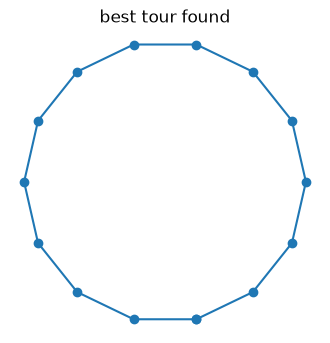

In [15]:
N_CITIES = 14
CITIES = [(math.cos(2 * math.pi * k / N_CITIES), math.sin(2 * math.pi * k / N_CITIES))
          for k in range(N_CITIES)]
shortest_possible = N_CITIES * 2 * math.sin(math.pi / N_CITIES)

for name, op in [("PMX", pmx), ("cycle", cycle_crossover)]:
    random.seed(4)
    best, fitness, history = evolve(tsp_problem(CITIES, crossover=op),
                                    population_size=200, generations=600,
                                    mutation_rate=0.08)
    print(f"{name:8} tour {-fitness:.3f}   best possible {shortest_possible:.3f}"
          f"   ratio {-fitness / shortest_possible:.2f}x")

xs = [CITIES[c][0] for c in best] + [CITIES[best[0]][0]]
ys = [CITIES[c][1] for c in best] + [CITIES[best[0]][1]]
plt.figure(figsize=(4, 4))
plt.plot(xs, ys, "-o")
plt.gca().set_aspect("equal")
plt.axis("off")
plt.title("best tour found")
plt.show()